# Heart Disease Prediction - Logistic Regression

Dataset: UCI Heart Disease, Cleveland subset (`processed.cleveland.data`)
Source: https://archive.ics.uci.edu/dataset/45/heart+disease

Educational project only, not a clinical tool.

## Imports

In [1]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, sklearn
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, RocCurveDisplay)

sns.set_theme()
out = "/kaggle/working" if os.path.exists("/kaggle/working") else "."
print(sklearn.__version__, pd.__version__, np.__version__)

1.9.1 3.0.6 2.5.4


## Load data

In [2]:
cols = ["age","sex","cp","trestbps","chol","fbs","restecg","thalach","exang","oldpeak","slope","ca","thal","num"]
path = (glob.glob("/kaggle/input/**/processed.cleveland.data", recursive=True)
        + glob.glob("**/processed.cleveland.data", recursive=True))[0]
print(path)
df = pd.read_csv(path, header=None, names=cols, na_values="?")
df.head()

processed.cleveland.data


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## Explore

In [3]:
print(df.shape)
df.info()

(303, 14)
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


## Missing values and duplicates

In [5]:
print(df.isna().sum()[df.isna().sum() > 0])
print("duplicates:", df.duplicated().sum())

ca      4
thal    2
dtype: int64
duplicates: 0


## Check invalid values

In [6]:
for c in ["sex","cp","fbs","restecg","exang","slope","ca","thal","num"]:
    print(c, sorted(df[c].dropna().unique()))

sex [np.float64(0.0), np.float64(1.0)]
cp [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]
fbs [np.float64(0.0), np.float64(1.0)]
restecg [np.float64(0.0), np.float64(1.0), np.float64(2.0)]
exang [np.float64(0.0), np.float64(1.0)]
slope [np.float64(1.0), np.float64(2.0), np.float64(3.0)]
ca [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0)]
thal [np.float64(3.0), np.float64(6.0), np.float64(7.0)]
num [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


## Target

The original `num` column is 0 to 4. 0 means no heart disease, 1-4 mean heart disease, so it is converted to binary.

In [7]:
df["target"] = (df["num"] > 0).astype(int)
print(df["num"].value_counts().sort_index())
print(df["target"].value_counts())
df = df.drop(columns="num")

num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64
target
0    164
1    139
Name: count, dtype: int64


## Target distribution

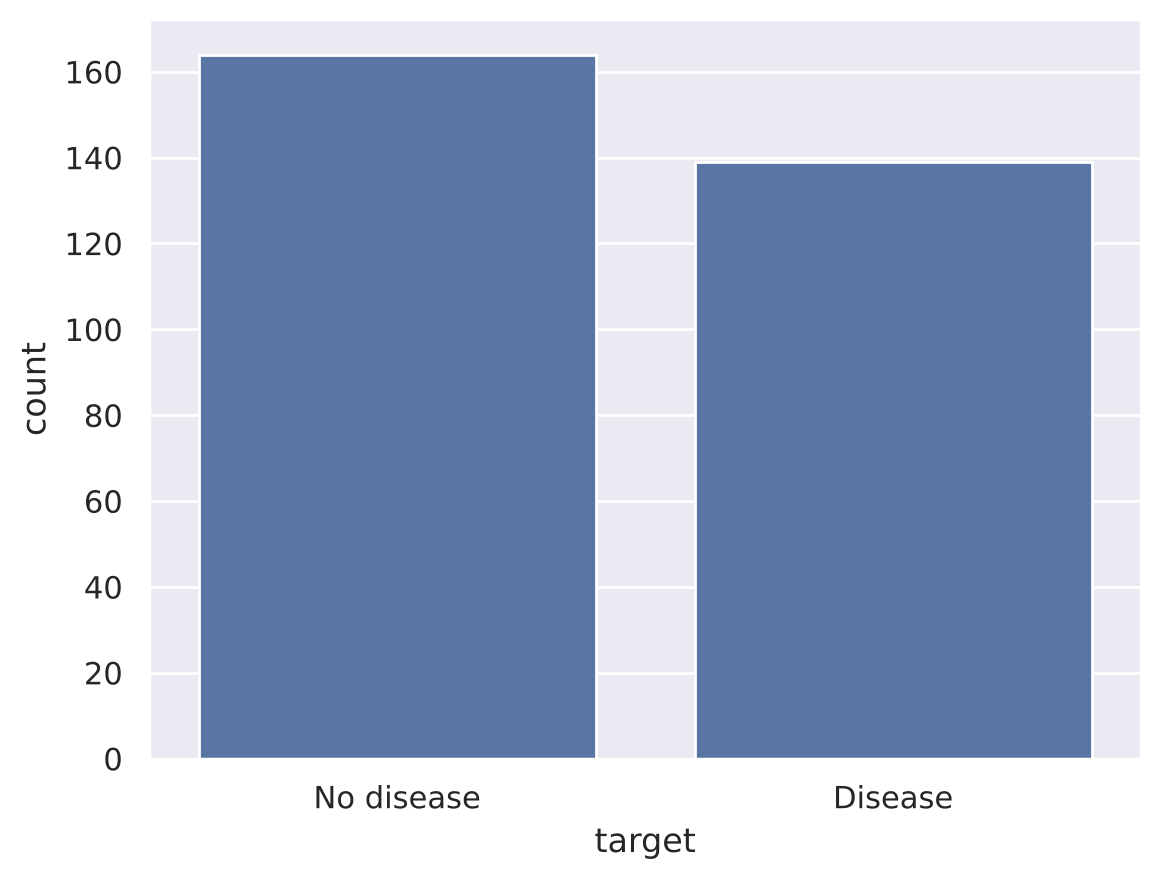

In [8]:
sns.countplot(x="target", data=df)
plt.xticks([0, 1], ["No disease", "Disease"])
plt.show()

## Numeric distributions

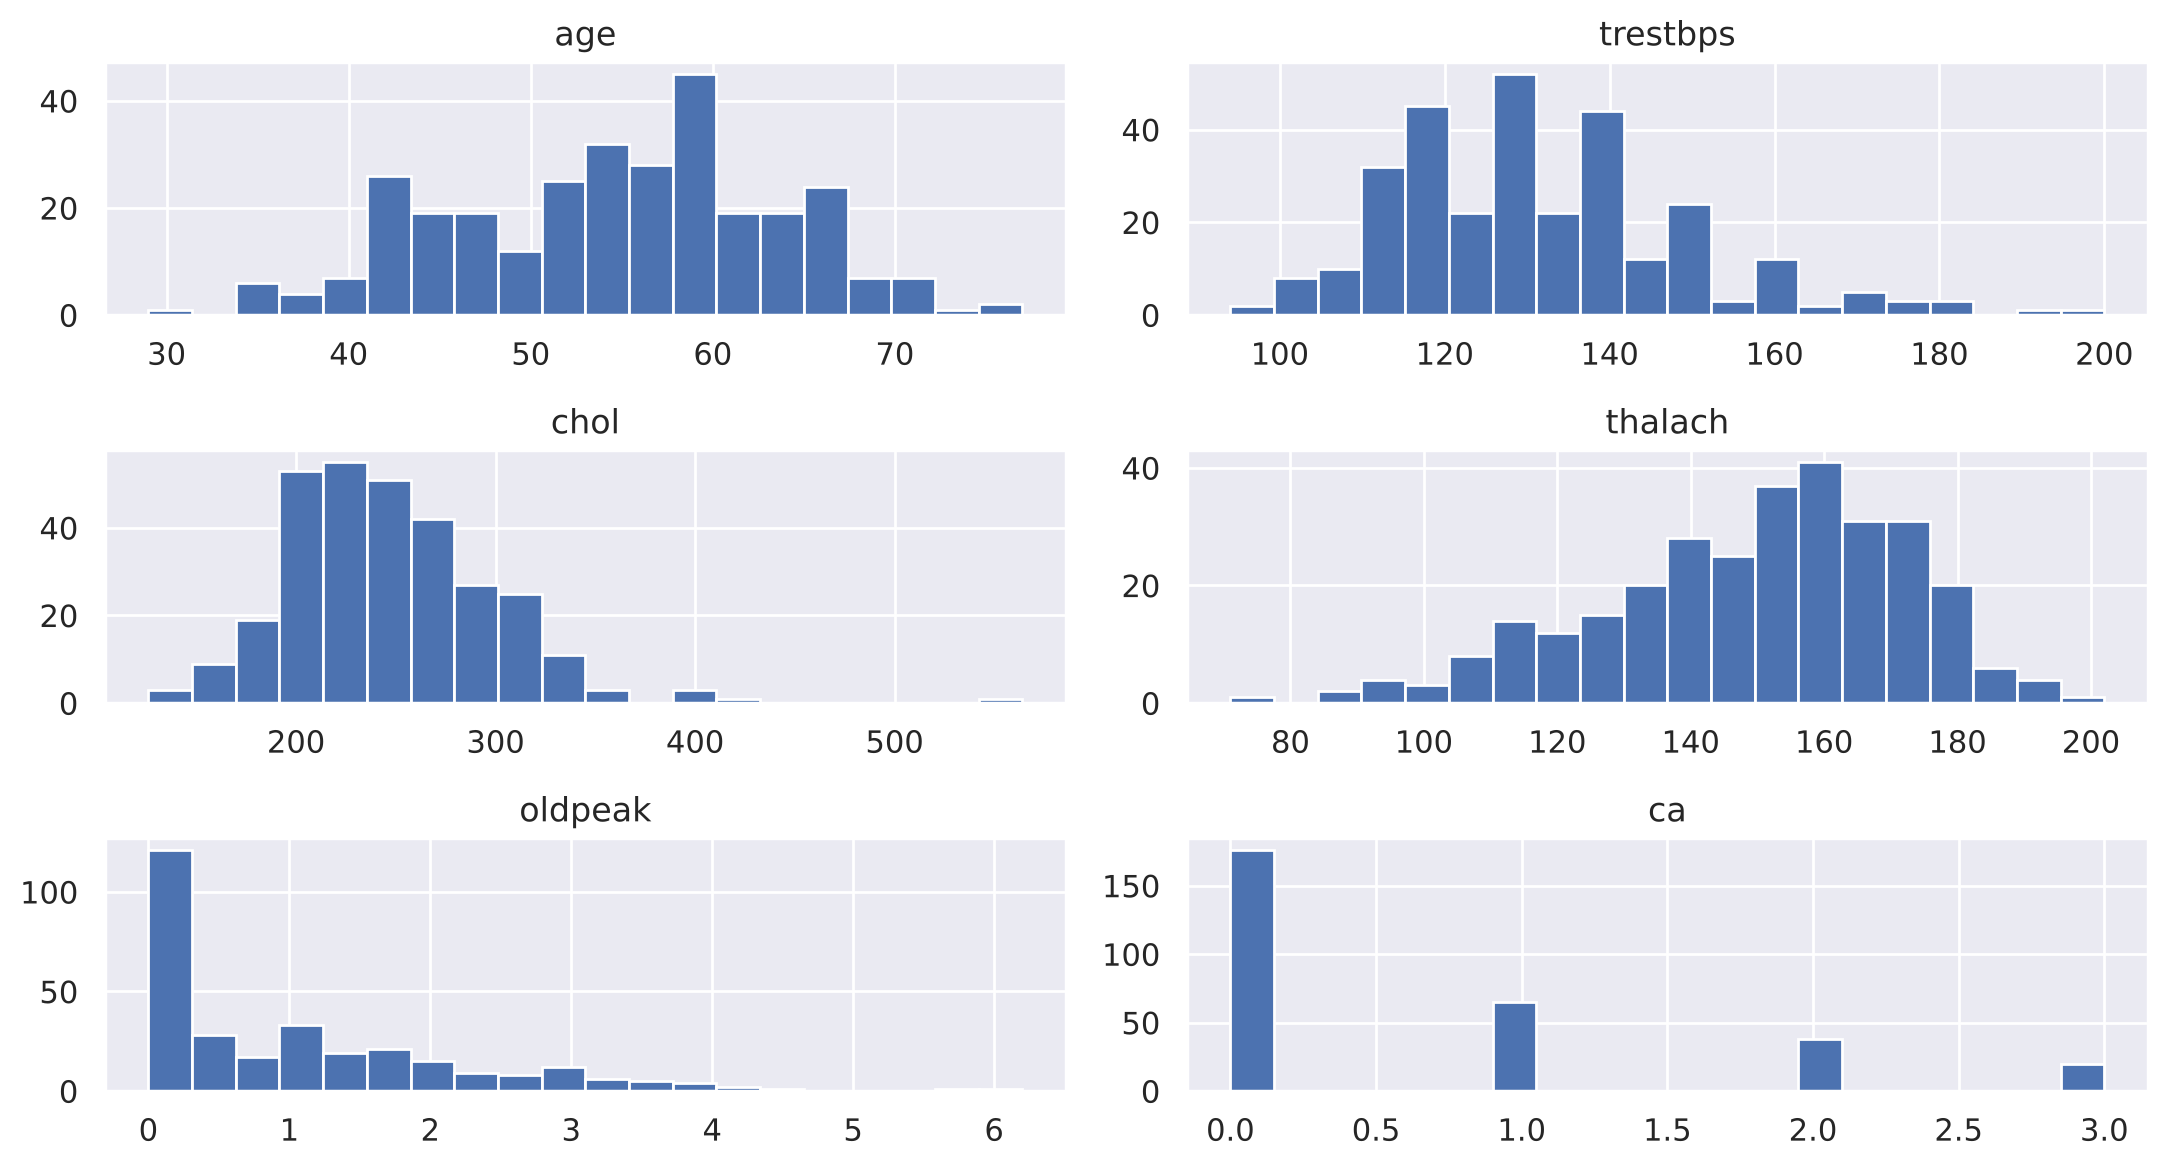

In [9]:
num = ["age","trestbps","chol","thalach","oldpeak","ca"]
cat = ["sex","cp","fbs","restecg","exang","slope","thal"]
df[num].hist(figsize=(11, 6), bins=20)
plt.tight_layout()
plt.show()

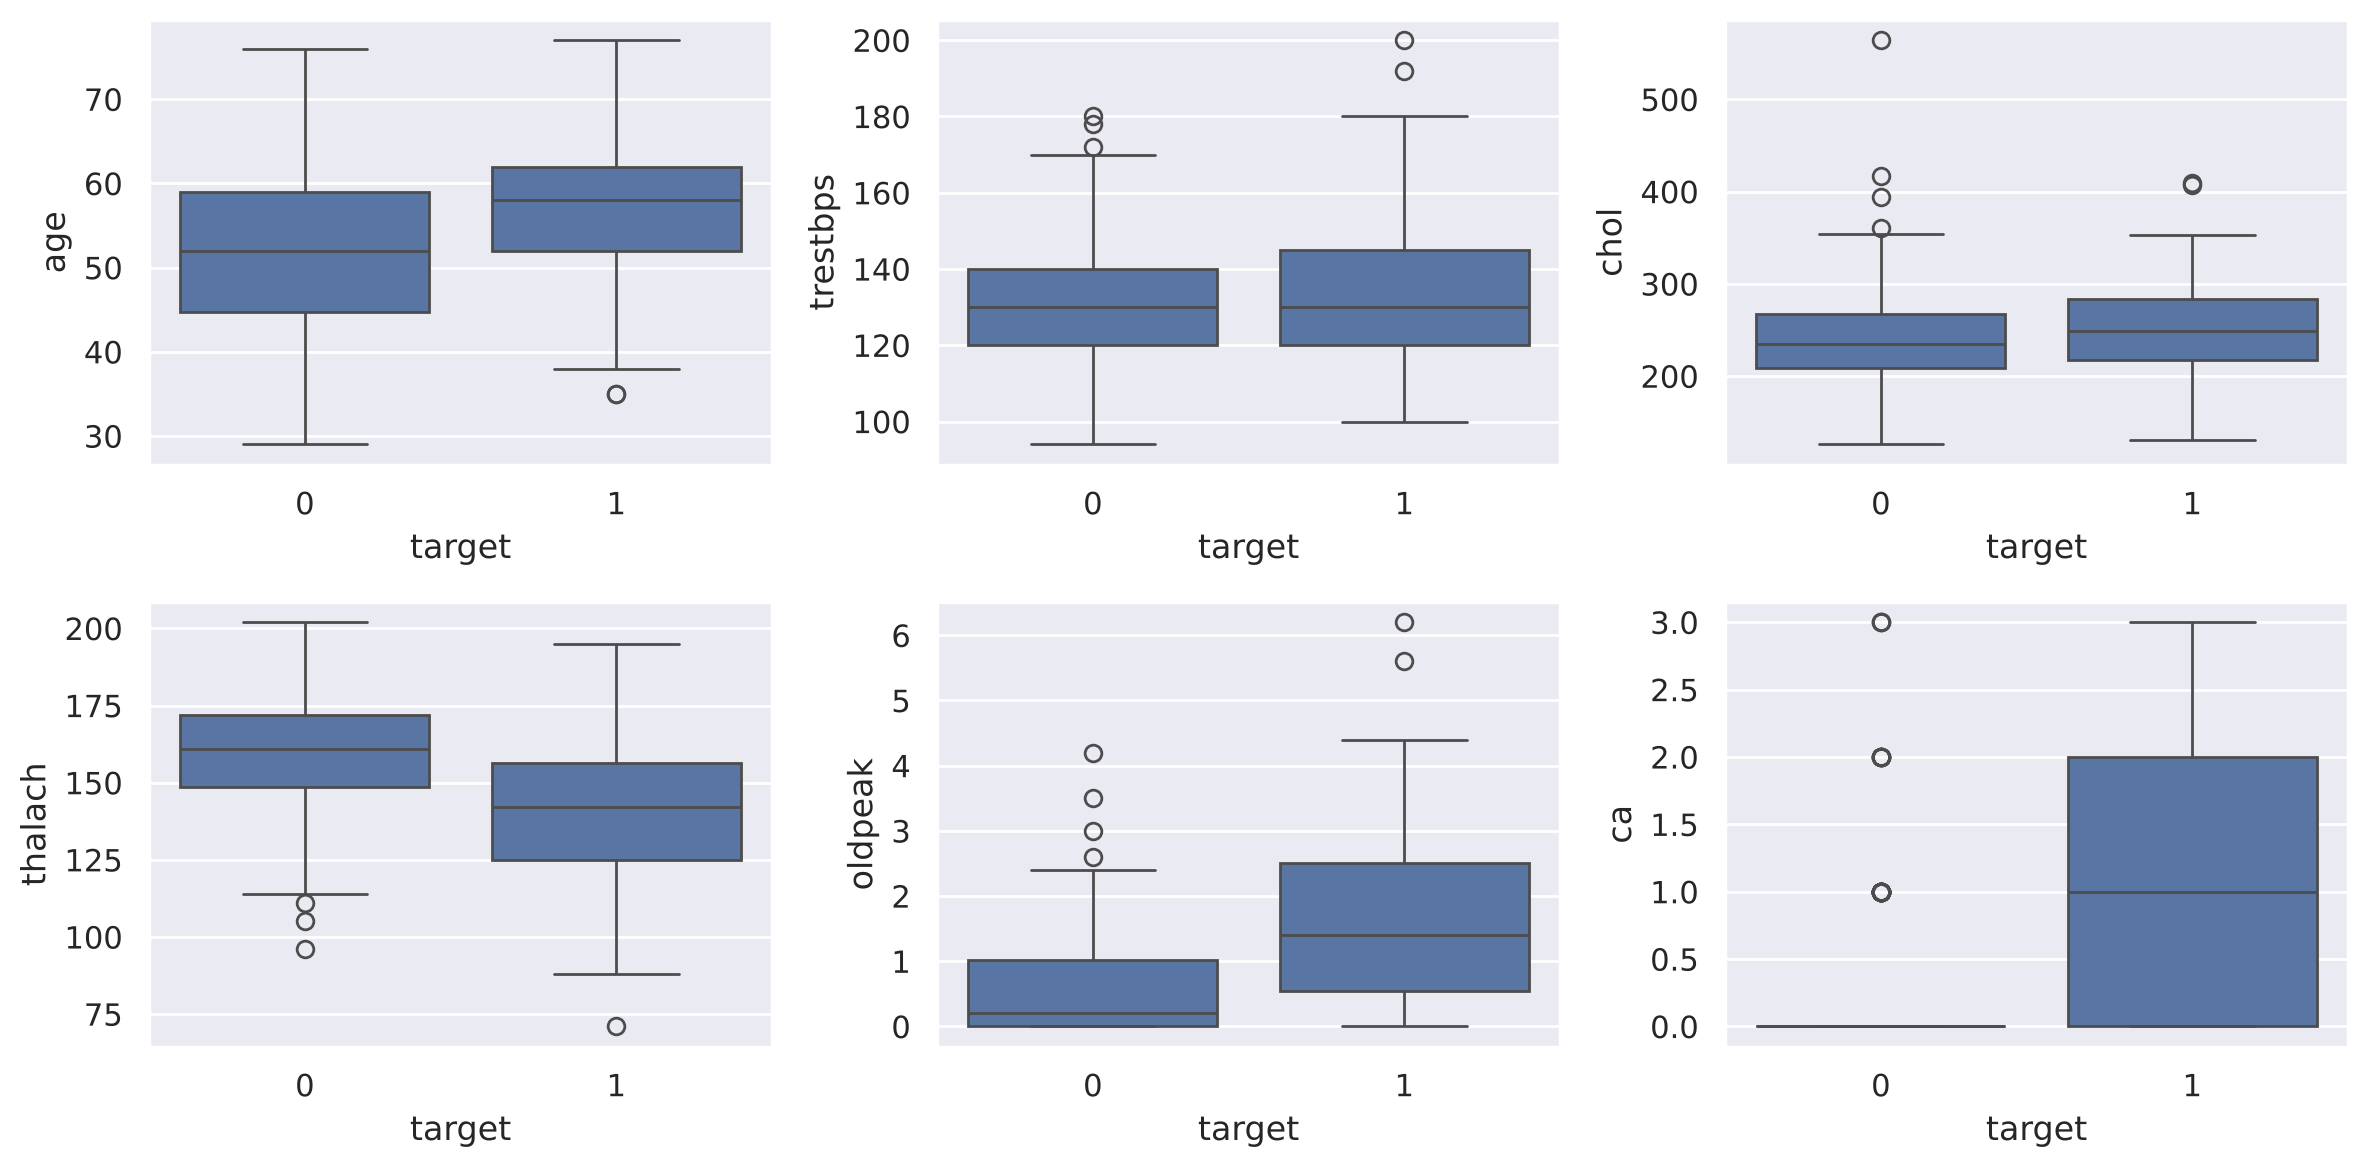

In [10]:
fig, ax = plt.subplots(2, 3, figsize=(12, 6))
for a, c in zip(ax.ravel(), num):
    sns.boxplot(x="target", y=c, data=df, ax=a)
plt.tight_layout()
plt.show()

## Categorical vs target

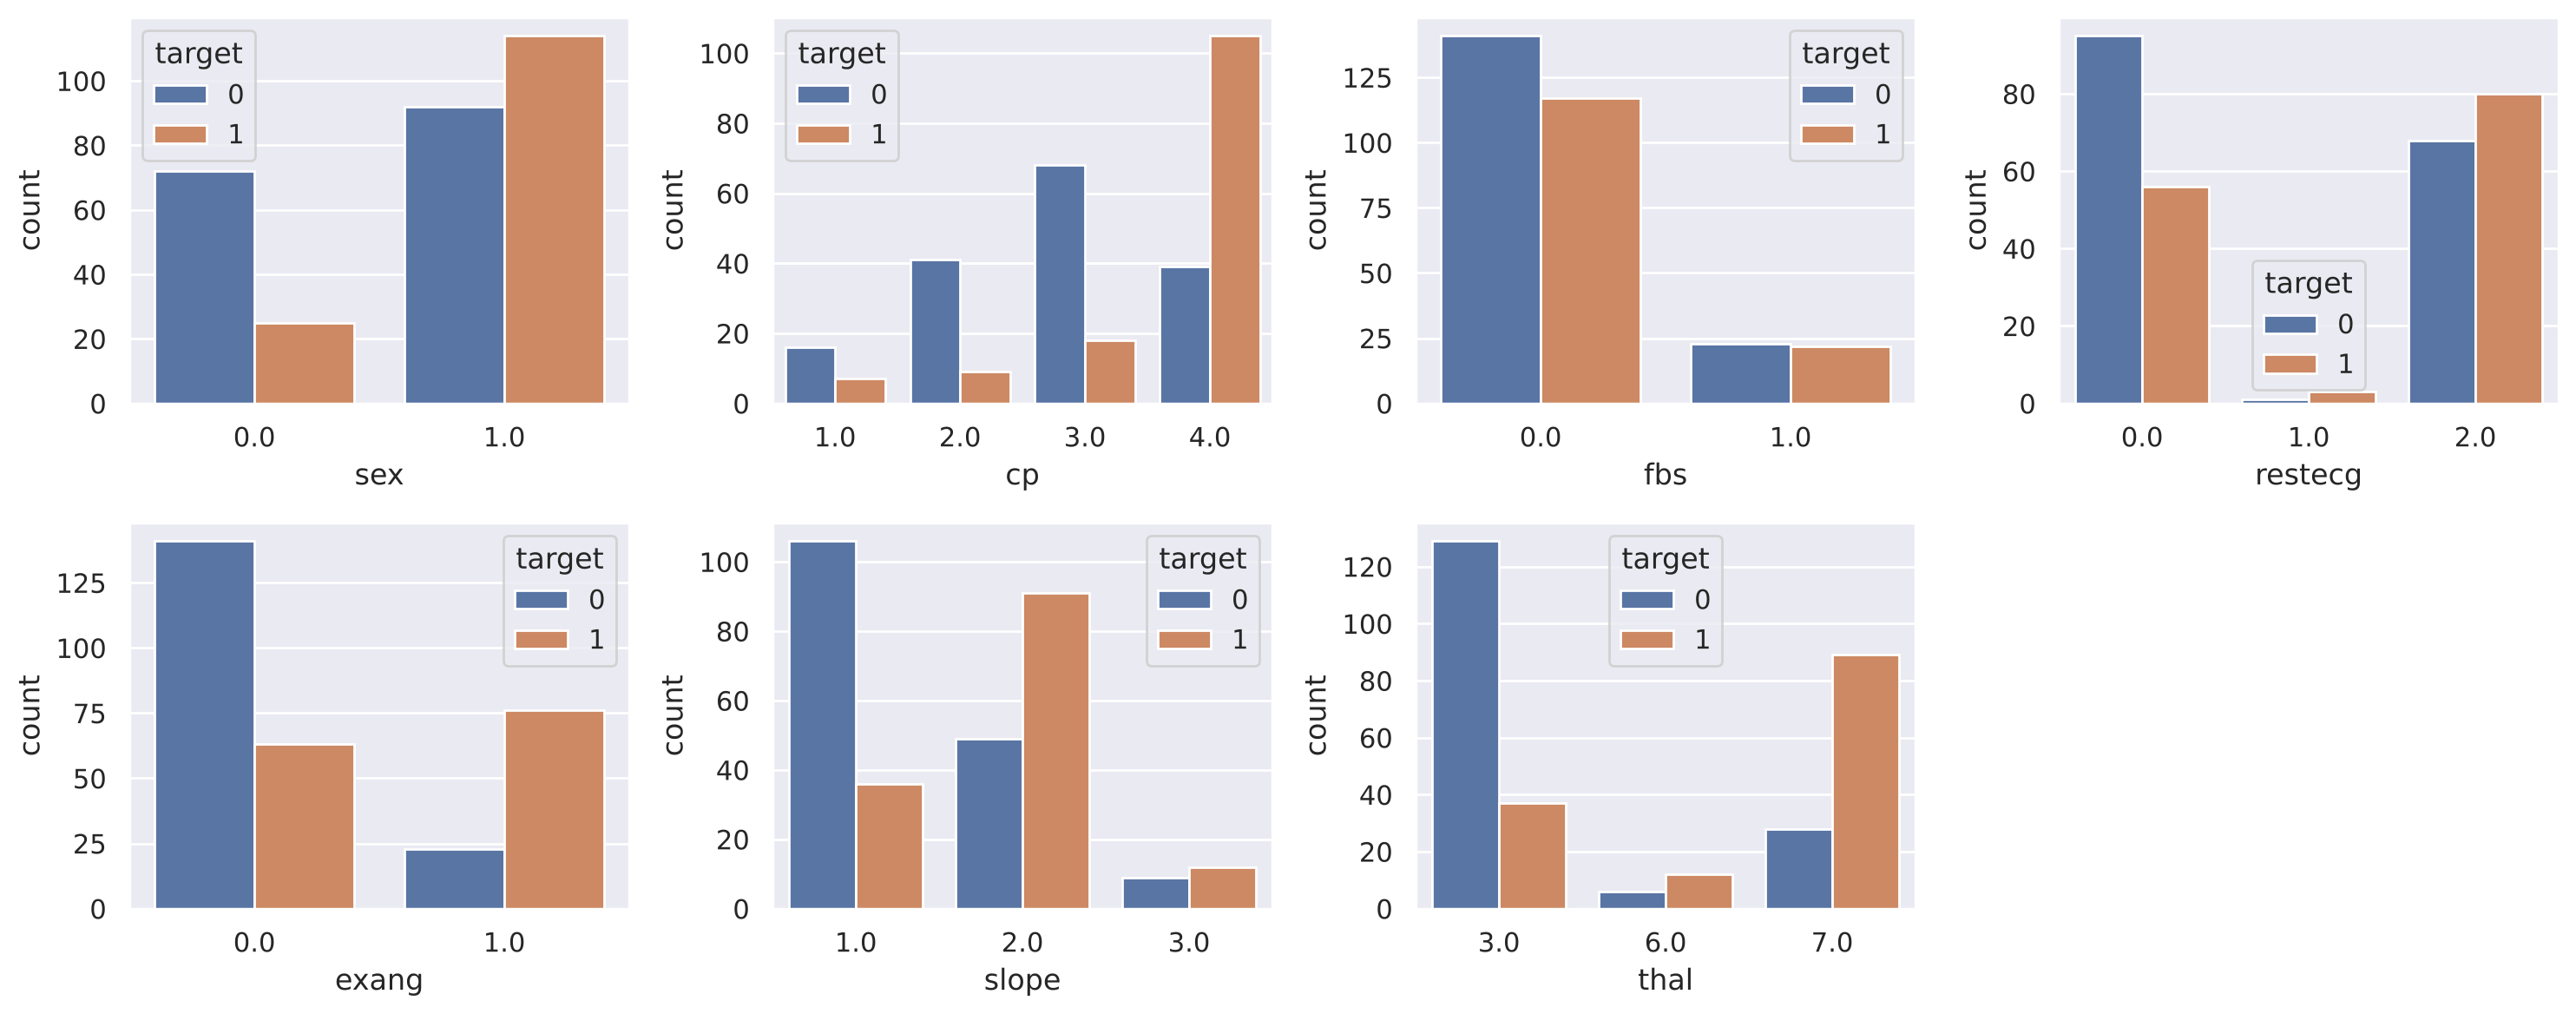

In [11]:
fig, ax = plt.subplots(2, 4, figsize=(15, 6))
for a, c in zip(ax.ravel(), cat):
    sns.countplot(x=c, hue="target", data=df, ax=a)
ax.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

## Correlation

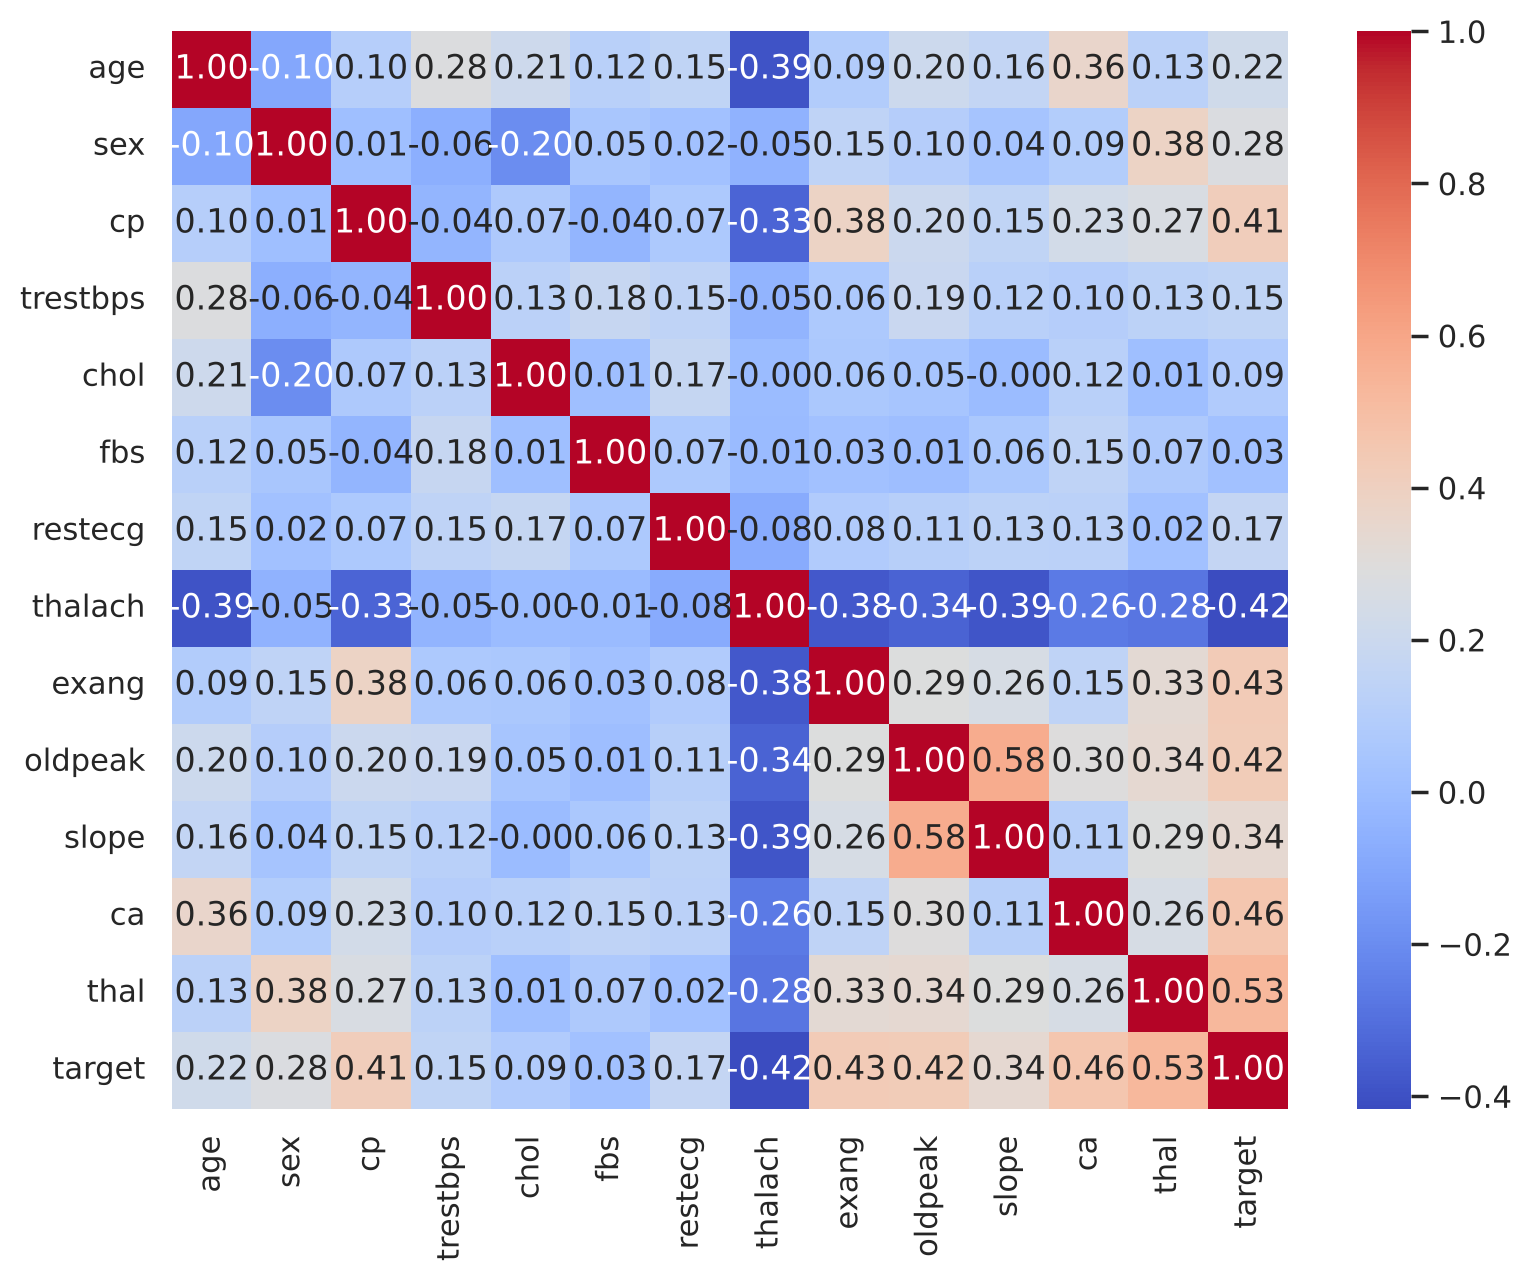

In [12]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

## Features and target

In [13]:
X = df.drop(columns="target")
y = df["target"]
print(X.shape, y.shape)

(303, 13) (303,)


## Train test split

In [14]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(X_tr.shape, X_te.shape)
print(y_tr.mean(), y_te.mean())

(242, 13) (61, 13)
0.45867768595041325 0.45901639344262296


## Pipeline

In [15]:
pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat),
])
pipe = Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=2000, random_state=42))])
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of 

## Hyperparameter search

L2 regularization strength `C` and class weight, tuned with stratified 5-fold CV on the training set only. The imputer, scaler and encoder are refit inside every fold, so there is no leakage.

In [16]:
grid = {"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30],
        "clf__class_weight": [None, "balanced"]}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
gs = GridSearchCV(pipe, grid, cv=cv, scoring="roc_auc", n_jobs=-1)
gs.fit(X_tr, y_tr)
print(gs.best_params_)
print("best cv roc_auc:", round(gs.best_score_, 4))

{'clf__C': 0.1, 'clf__class_weight': None}
best cv roc_auc: 0.9113


In [17]:
res = pd.DataFrame(gs.cv_results_)
res[["param_clf__C","param_clf__class_weight","mean_test_score","std_test_score","rank_test_score"]].sort_values("rank_test_score").head(8)

,param_clf__C,param_clf__class_weight,mean_test_score,std_test_score,rank_test_score
4,0.1,NaN,0.911344,0.017971,1
5,0.1,balanced,0.911329,0.018330,2
6,0.3,NaN,0.908897,0.018659,3
7,0.3,balanced,0.907878,0.018156,4
11,3.0,balanced,0.906890,0.016527,5
9,1.0,balanced,0.906523,0.017576,6
8,1.0,NaN,0.906495,0.019701,7
13,10.0,balanced,0.905561,0.014485,8


## Test set evaluation

In [18]:
best = gs.best_estimator_
pred = best.predict(X_te)
prob = best.predict_proba(X_te)[:, 1]
m = {"accuracy": accuracy_score(y_te, pred), "precision": precision_score(y_te, pred),
     "recall": recall_score(y_te, pred), "f1": f1_score(y_te, pred), "roc_auc": roc_auc_score(y_te, prob)}
pd.Series(m).round(4)

accuracy     0.8852
precision    0.8387
recall       0.9286
f1           0.8814
roc_auc      0.9610
dtype: float64

In [19]:
print(classification_report(y_te, pred, target_names=["No disease", "Disease"]))

              precision    recall  f1-score   support

  No disease       0.93      0.85      0.89        33
     Disease       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61



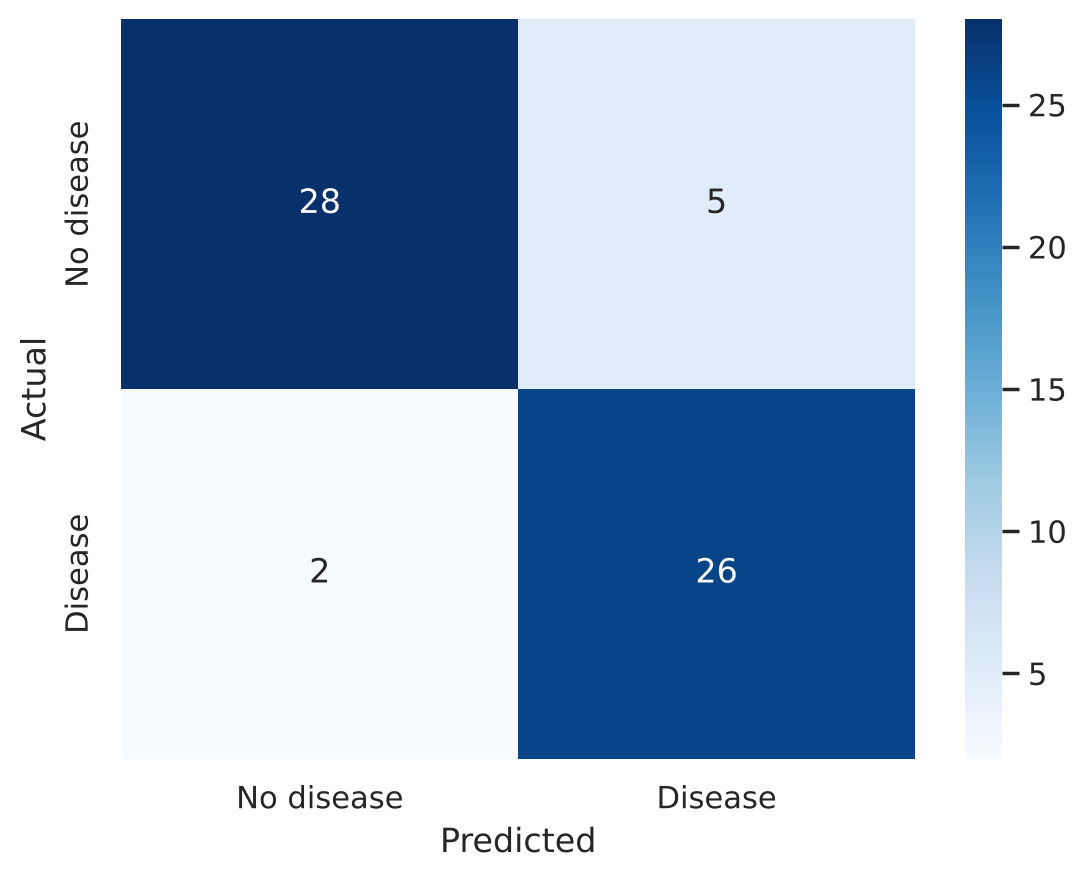

In [20]:
sns.heatmap(confusion_matrix(y_te, pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["No disease", "Disease"], yticklabels=["No disease", "Disease"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

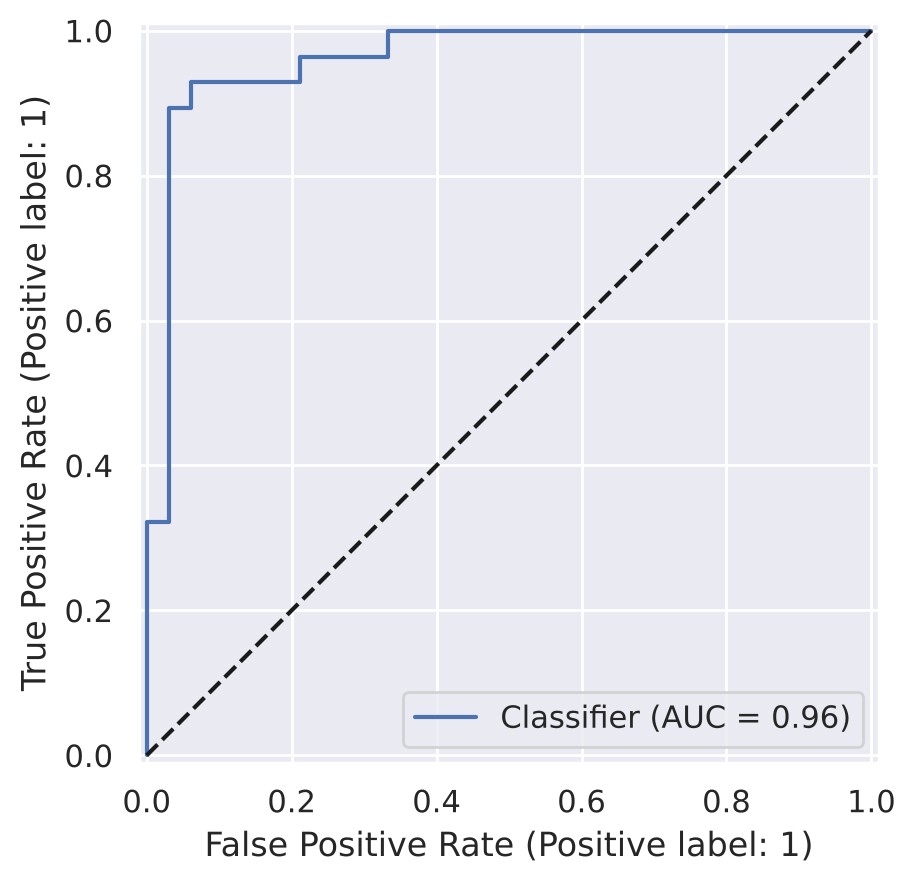

In [21]:
RocCurveDisplay.from_predictions(y_te, prob)
plt.plot([0, 1], [0, 1], "k--")
plt.show()

The test set has only 61 patients, so these numbers can shift noticeably with a different split. Treat them as rough estimates.

## Cross-validation on training set

In [22]:
from sklearn.model_selection import cross_validate
cvr = cross_validate(clone(best), X_tr, y_tr, cv=cv, scoring=["accuracy","precision","recall","f1","roc_auc"])
pd.DataFrame({k[5:]: [v.mean(), v.std()] for k, v in cvr.items() if k.startswith("test_")}, index=["mean","std"]).round(4)

,accuracy,precision,recall,f1,roc_auc
mean,0.8511,0.8776,0.7921,0.8299,0.9113
std,0.0250,0.0606,0.0482,0.0260,0.0180


## Coefficients

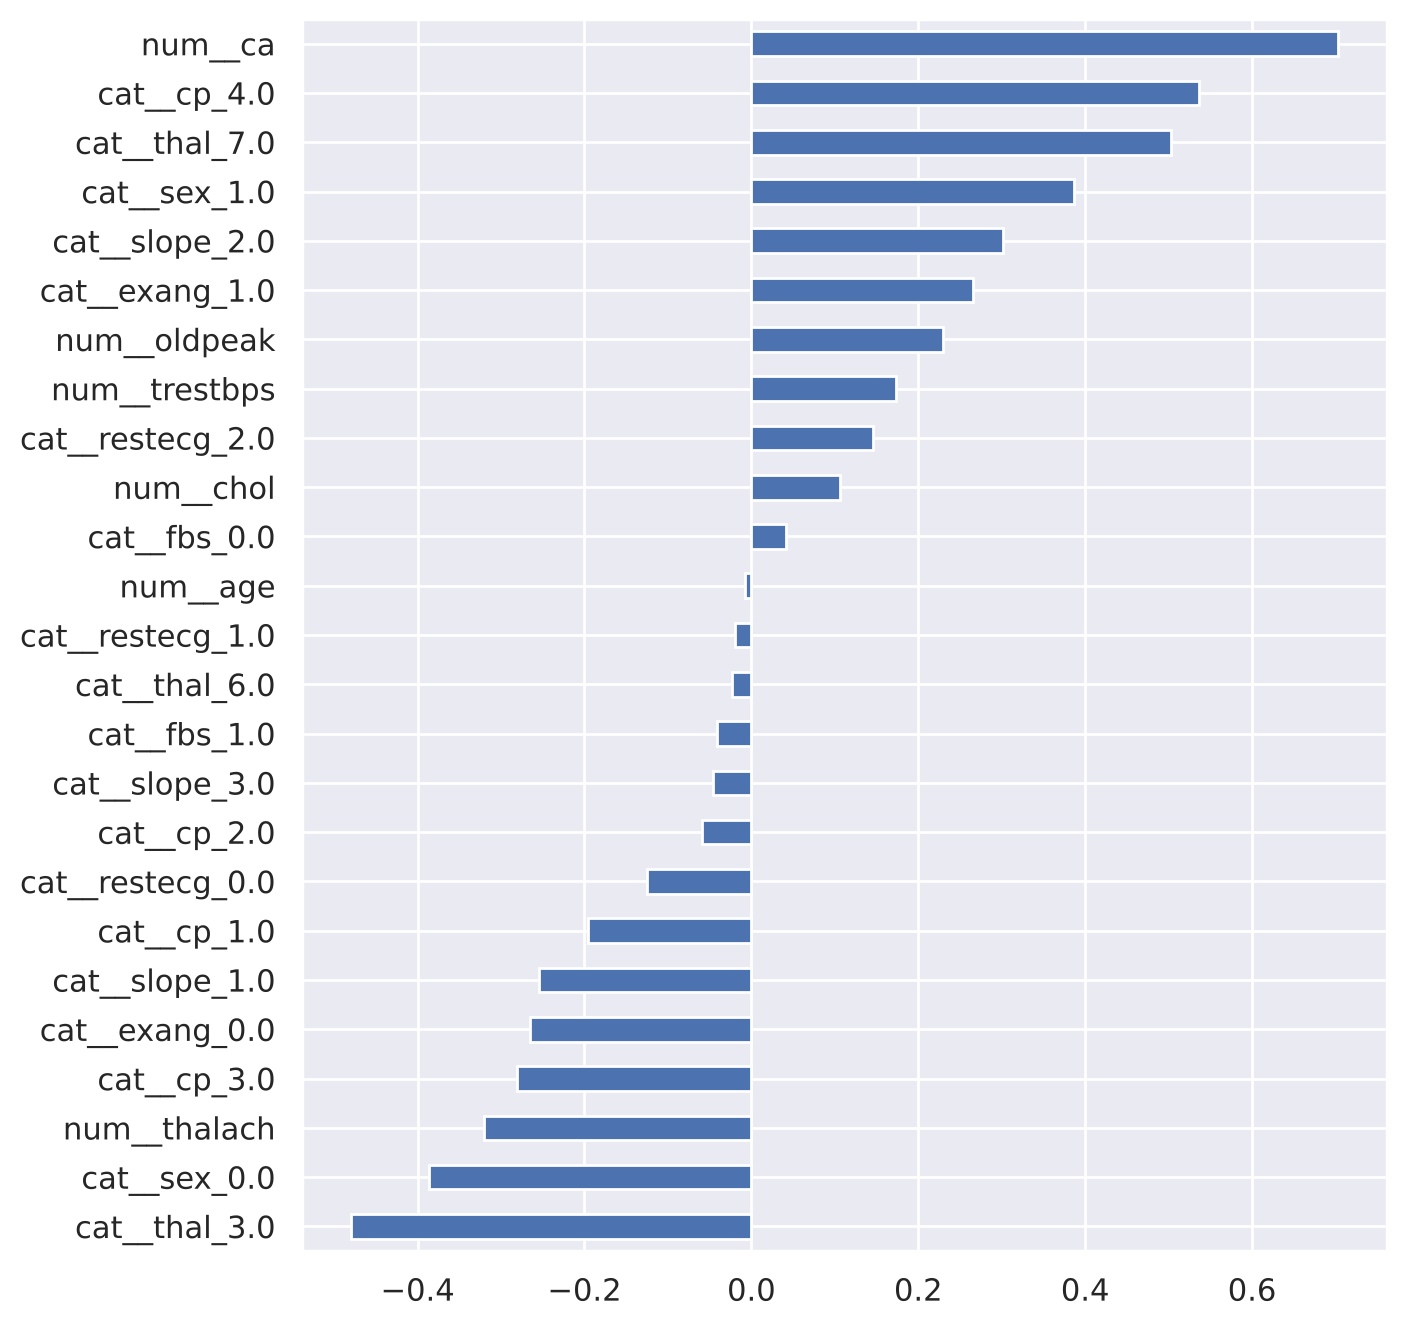

In [23]:
names = best.named_steps["pre"].get_feature_names_out()
coef = pd.Series(best.named_steps["clf"].coef_[0], index=names).sort_values()
coef.plot(kind="barh", figsize=(7, 8))
plt.show()

## Final model

The model above was trained on 80% of the data. For deployment it is refit on all 303 rows with the chosen hyperparameters. The test metrics above belong to the 80% model; the final model has no separate held-out score.

In [24]:
final = clone(best).fit(X, y)
print(final.classes_)

[0 1]


## Save model

In [25]:
joblib.dump(final, out + "/heart_disease_model.pkl")
with open(out + "/model_versions.txt", "w") as f:
    f.write(f"scikit-learn=={sklearn.__version__}\npandas=={pd.__version__}\nnumpy=={np.__version__}\njoblib=={joblib.__version__}\n")
print(open(out + "/model_versions.txt").read())
print(os.path.getsize(out + "/heart_disease_model.pkl"), "bytes")

scikit-learn==1.9.1
pandas==3.0.6
numpy==2.5.4
joblib==1.6.0

4730 bytes


## Reload and compare

In [26]:
model = joblib.load(out + "/heart_disease_model.pkl")
print(np.array_equal(model.predict(X), final.predict(X)))
print(np.allclose(model.predict_proba(X), final.predict_proba(X)))

True
True


## Sample patients

In [27]:
s = pd.DataFrame([
    [41, 0, 2, 130, 204, 0, 2, 172, 0, 1.4, 1, 0, 3],
    [67, 1, 4, 160, 286, 0, 2, 108, 1, 1.5, 2, 3, 3],
], columns=X.columns).astype(float)
p = model.predict_proba(s)
for i in range(len(s)):
    print(model.predict(s)[i], p[i].round(3))

0 [0.919 0.081]
1 [0.017 0.983]


## Load in a separate process

In [28]:
import subprocess, sys
t = f'''
import joblib, pandas as pd
m = joblib.load("{out}/heart_disease_model.pkl")
d = pd.DataFrame([[67,1,4,160,286,0,2,108,1,1.5,2,3,3]], columns={list(X.columns)}).astype(float)
print(m.predict(d), m.predict_proba(d).round(3))
'''
r = subprocess.run([sys.executable, "-c", t], capture_output=True, text=True)
print(r.stdout, r.stderr)

[1] [[0.017 0.983]]
 


## Output files

In [29]:
print(sorted(os.listdir(out)))

['Index', 'WARNING', 'ask-detrano', 'bak', 'cleve.mod', 'cleveland.data', 'costs', 'heart-disease.names', 'heart_disease_logistic_regression.ipynb', 'heart_disease_model.pkl', 'hungarian.data', 'long-beach-va.data', 'model_versions.txt', 'new.data', 'processed.cleveland.data', 'processed.hungarian.data', 'processed.switzerland.data', 'processed.va.data', 'reprocessed.hungarian.data', 'switzerland.data']
